# Chapter 2 · Matrices as maps

*Book 1 · Linear Algebra · Shelf I*

**Builds on:** [Chapter 1](01-vectors-and-spaces.ipynb) -- vectors, combinations, rank.
**You will:** read a matrix as a machine that moves every point of space, see rotation, scaling,
shearing and projection as matrices, compose them, and measure with the determinant how much a
map stretches area.

A matrix $A$ turns a vector $x$ into a new vector $Ax$. Its columns say where the basis vectors
go; everything else follows by linearity. Reading matrices this way -- as maps -- makes the rest
of the book visual.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from ds_toolbox import viz

viz.use_style()

# a grid and a unit square, to watch them move
lines = np.linspace(-1, 1, 9)
grid = [np.array([[x, x], [-1, 1]]) for x in lines] + [np.array([[-1, 1], [y, y]]) for y in lines]
square = np.array([[0, 1, 1, 0, 0], [0, 0, 1, 1, 0]], dtype=float)


def show(ax, A, title):
    for g in grid:
        ax.plot(*(A @ g), color="0.8", lw=0.8)
    ax.fill(*(A @ square), alpha=0.4, color=viz.PALETTE[0])
    for col, colour in zip(A.T, [viz.PALETTE[3], viz.PALETTE[2]], strict=True):
        ax.annotate("", xy=col, xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": colour, "lw": 2})
    ax.set(xlim=(-2, 2), ylim=(-2, 2), aspect="equal", title=title)
    ax.grid(False)

## Five maps

The red and green arrows are the matrix's columns: where $e_1 = (1, 0)$ and $e_2 = (0, 1)$ land.
The shaded square is where the unit square lands.

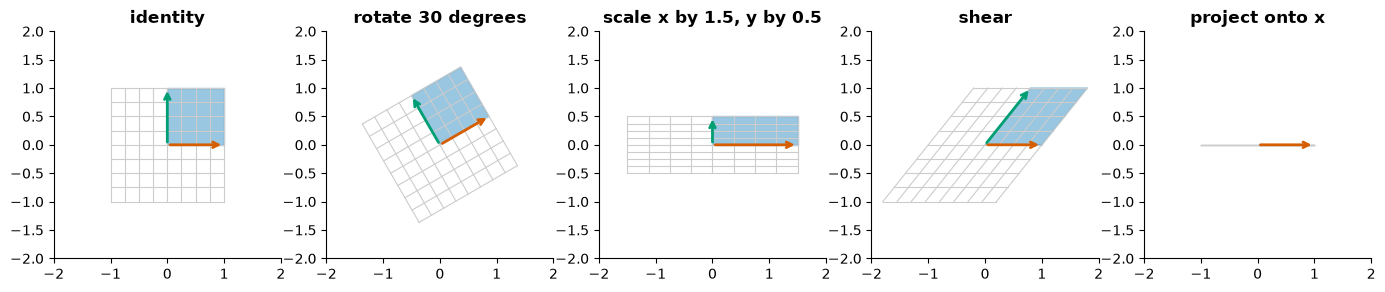

In [2]:
t = np.radians(30)
maps = {
    "identity": np.eye(2),
    "rotate 30 degrees": np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]]),
    "scale x by 1.5, y by 0.5": np.diag([1.5, 0.5]),
    "shear": np.array([[1, 0.8], [0, 1]]),
    "project onto x": np.array([[1, 0], [0, 0]]),
}
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, (name, A) in zip(axes, maps.items(), strict=True):
    show(ax, A, name)

## Composition is multiplication

Applying $B$ after $A$ is the single map $BA$. Order matters: rotating then shearing is not
shearing then rotating.

S R == R S ? False


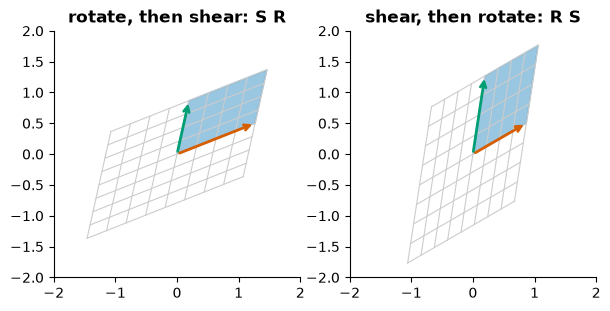

In [3]:
R, S = maps["rotate 30 degrees"], maps["shear"]
fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
show(axes[0], S @ R, "rotate, then shear: S R")
show(axes[1], R @ S, "shear, then rotate: R S")
print("S R == R S ?", np.allclose(S @ R, R @ S))

## The determinant: how much area changes

The **determinant** is the factor by which a map scales area (volume, in higher dimensions),
with a sign that says whether it flips orientation. A determinant of 0 means the map squashes the
plane onto a line or a point: information is lost, and the map has no inverse.

In [4]:
for name, A in maps.items():
    print(f"{name:28s} det = {np.linalg.det(A):6.3f}")

identity                     det =  1.000
rotate 30 degrees            det =  1.000
scale x by 1.5, y by 0.5     det =  0.750
shear                        det =  1.000
project onto x               det =  0.000


Rotation and shear keep area (det 1); the projection destroys it (det 0). Determinants multiply:
$\det(BA) = \det(B)\det(A)$.

In [5]:
print("det(S R) =", round(np.linalg.det(S @ R), 6),
      "= det(S) det(R) =", round(np.linalg.det(S) * np.linalg.det(R), 6))

det(S R) = 1.0 = det(S) det(R) = 1.0


## Undoing a map

A map with a non-zero determinant can be undone: its **inverse** $A^{-1}$ sends every $Ax$ back
to $x$. A rotation's inverse is the rotation the other way, which is also its transpose.

In [6]:
x = np.array([0.7, -0.3])
print("R^-1 R x =", np.linalg.inv(R) @ R @ x, "| R^-1 == R^T ?", np.allclose(np.linalg.inv(R), R.T))

R^-1 R x = [ 0.7 -0.3] | R^-1 == R^T ? True


## What to remember

- A matrix is a map; its columns are where the basis vectors go.
- Composing maps multiplies matrices, and order matters.
- The determinant is the area factor; zero means information is lost and no inverse exists.

## Exercises

1. Write the matrix that reflects the plane across the line $y = x$. What is its determinant?
2. Find two matrices $A, B$ with $AB = BA$ that are not multiples of the identity.
3. Apply the shear ten times. What does the square look like, and what is the determinant?

**Next:** [Chapter 3 · Solving systems](03-solving-systems.ipynb)